In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ds = pd.read_csv("hcvdat0.csv")
ds = ds.iloc[:, 1:]

target = "Category"

X = ds.drop(columns=[target])
y = ds[target]

print(X.head())

   Age Sex   ALB   ALP   ALT   AST   BIL    CHE  CHOL   CREA   GGT  PROT
0   32   m  38.5  52.5   7.7  22.1   7.5   6.93  3.23  106.0  12.1  69.0
1   32   m  38.5  70.3  18.0  24.7   3.9  11.17  4.80   74.0  15.6  76.5
2   32   m  46.9  74.7  36.2  52.6   6.1   8.84  5.20   86.0  33.2  79.3
3   32   m  43.2  52.0  30.6  22.6  18.9   7.33  4.74   80.0  33.8  75.7
4   32   m  39.2  74.1  32.6  24.8   9.6   9.15  4.32   76.0  29.9  68.7


In [11]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(numeric_features)
print(categorical_features)

['Age', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']
['Sex']


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) 
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

X_processed = preprocessor.fit_transform(X)

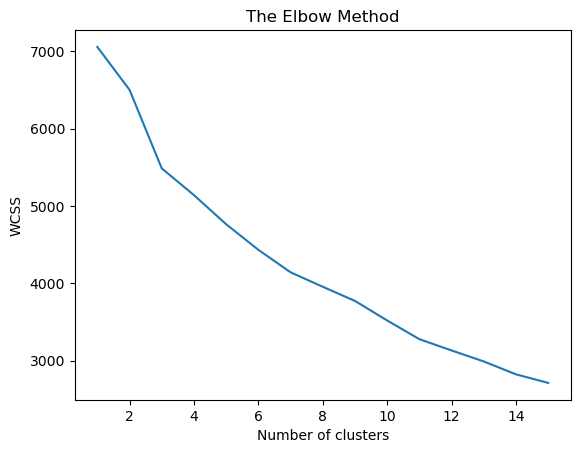

In [20]:
import os
os.environ["OMP_NUM_THREADS"] = "3"

import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')

from sklearn.cluster import KMeans
wcss = []
for i in range(1,16):
  kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
  kmeans.fit(X_processed)
  wcss.append(kmeans.inertia_)

plt.plot(range(1,16), wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [21]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init="auto")
y_kmeans = kmeans.fit_predict(X_processed)

ds['Cluster'] = y_kmeans

print(ds.head())

        Category  Age Sex   ALB   ALP   ALT   AST   BIL    CHE  CHOL   CREA  \
0  0=Blood Donor   32   m  38.5  52.5   7.7  22.1   7.5   6.93  3.23  106.0   
1  0=Blood Donor   32   m  38.5  70.3  18.0  24.7   3.9  11.17  4.80   74.0   
2  0=Blood Donor   32   m  46.9  74.7  36.2  52.6   6.1   8.84  5.20   86.0   
3  0=Blood Donor   32   m  43.2  52.0  30.6  22.6  18.9   7.33  4.74   80.0   
4  0=Blood Donor   32   m  39.2  74.1  32.6  24.8   9.6   9.15  4.32   76.0   

    GGT  PROT  Cluster  
0  12.1  69.0        2  
1  15.6  76.5        2  
2  33.2  79.3        2  
3  33.8  75.7        2  
4  29.9  68.7        2  


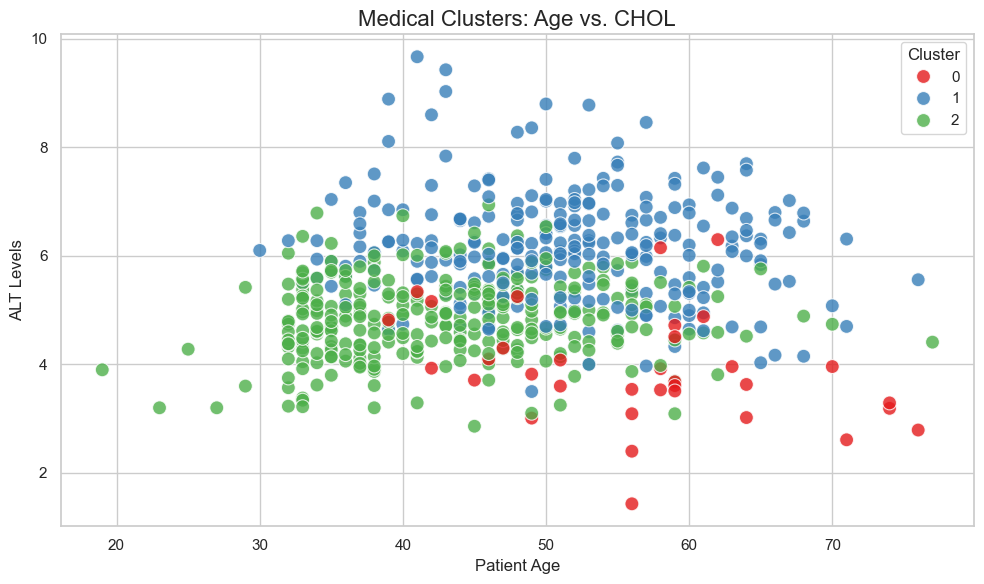

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Set a clean Seaborn theme
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# 2. Build the Scatterplot
# Simply pass your entire dataframe, and tell Seaborn which columns to compare
sns.scatterplot(
    data=ds, 
    x='Age',       # Change this to any column you want to explore! (e.g., 'ALB')
    y='CHOL',       # Change this to any other column! (e.g., 'CHOL')
    hue='Cluster', # This automatically colors the dots by their cluster (0, 1, or 2)
    palette='Set1', # A bright, distinct Seaborn color palette
    s=100,         # Dot size
    alpha=0.8      # Makes the dots slightly transparent so you can see overlaps
)

# 3. Fix the Tutorial Labels
plt.title('Medical Clusters: Age vs. CHOL', fontsize=16)
plt.xlabel('Patient Age', fontsize=12)
plt.ylabel('ALT Levels', fontsize=12)

# 4. Clean up the legend and show
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

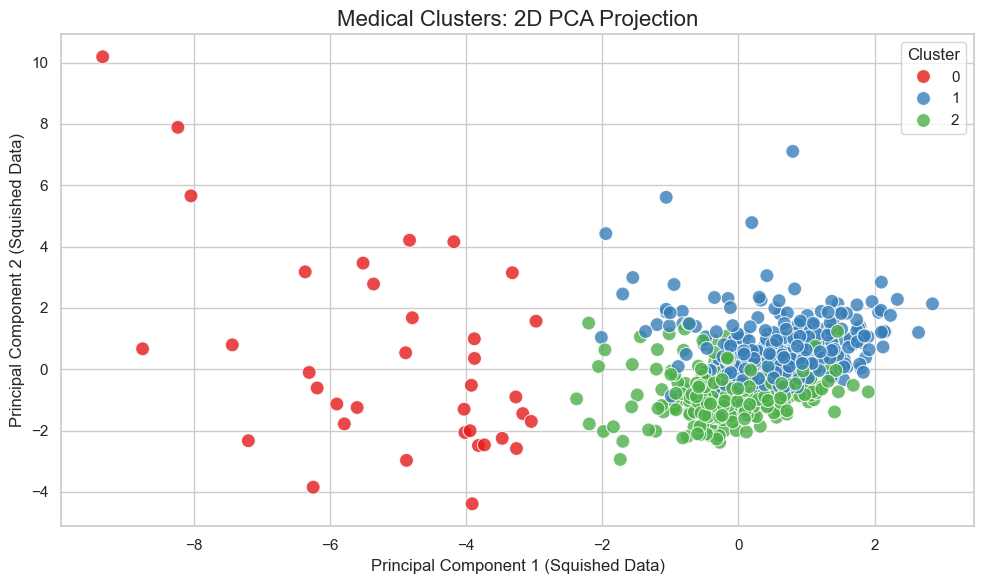

In [32]:
from sklearn.decomposition import PCA

# 1. Initialize PCA to squish our 12D data down to 2 dimensions
pca = PCA(n_components=2)

# 2. Fit and transform your SCALED data (X_processed)
X_pca = pca.fit_transform(X_processed)

# 3. Add these new 2D coordinates to your dataset
ds['PCA1'] = X_pca[:, 0]
ds['PCA2'] = X_pca[:, 1]

# 4. Graph the PCA flat-map!
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=ds, 
    x='PCA1', 
    y='PCA2', 
    hue='Cluster', 
    palette='Set1', 
    s=100, 
    alpha=0.8
)

plt.title('Medical Clusters: 2D PCA Projection', fontsize=16)
plt.xlabel('Principal Component 1 (Squished Data)', fontsize=12)
plt.ylabel('Principal Component 2 (Squished Data)', fontsize=12)
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

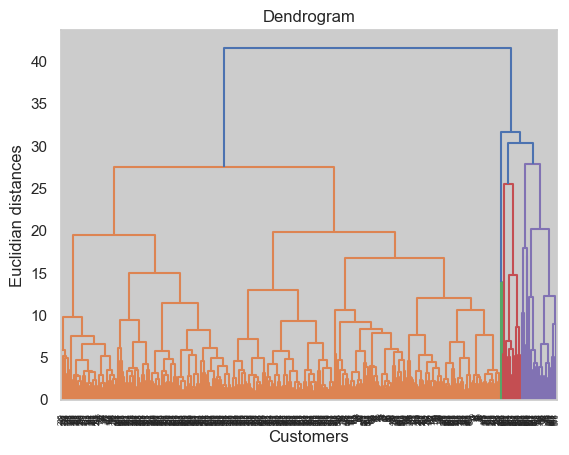

In [36]:
import scipy.cluster.hierarchy as sch
dendrogram = sch.dendrogram(sch.linkage(X_processed, method='ward'))
plt.plot()
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidian distances')
plt.show()

In [44]:
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters = 4, metric = 'euclidean', linkage='ward')
y_hc = hc.fit_predict(X_processed)

ds['Cluster'] = y_hc

print(ds.head())

        Category  Age Sex   ALB   ALP   ALT   AST   BIL    CHE  CHOL   CREA  \
0  0=Blood Donor   32   m  38.5  52.5   7.7  22.1   7.5   6.93  3.23  106.0   
1  0=Blood Donor   32   m  38.5  70.3  18.0  24.7   3.9  11.17  4.80   74.0   
2  0=Blood Donor   32   m  46.9  74.7  36.2  52.6   6.1   8.84  5.20   86.0   
3  0=Blood Donor   32   m  43.2  52.0  30.6  22.6  18.9   7.33  4.74   80.0   
4  0=Blood Donor   32   m  39.2  74.1  32.6  24.8   9.6   9.15  4.32   76.0   

    GGT  PROT      PCA1      PCA2  Cluster  
0  12.1  69.0 -0.410545 -2.006584        1  
1  15.6  76.5  1.123365 -0.115842        1  
2  33.2  79.3  1.042007  0.902788        1  
3  33.8  75.7  0.441534 -0.469186        1  
4  29.9  68.7 -0.039613 -0.522597        1  


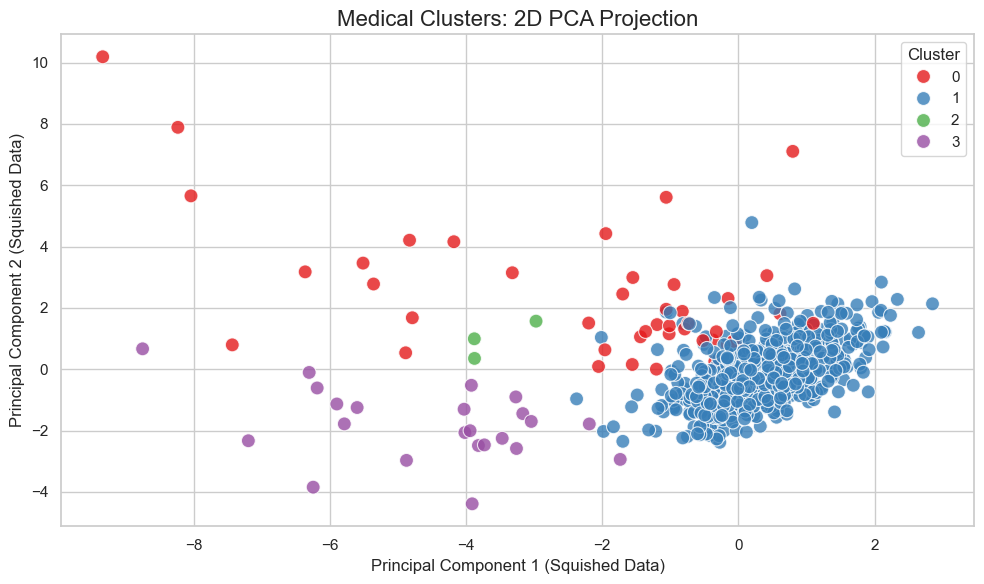

In [45]:
from sklearn.decomposition import PCA

# 1. Initialize PCA to squish our 12D data down to 2 dimensions
pca = PCA(n_components=2)

# 2. Fit and transform your SCALED data (X_processed)
X_pca = pca.fit_transform(X_processed)

# 3. Add these new 2D coordinates to your dataset
ds['PCA1'] = X_pca[:, 0]
ds['PCA2'] = X_pca[:, 1]

# 4. Graph the PCA flat-map!
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=ds, 
    x='PCA1', 
    y='PCA2', 
    hue='Cluster', 
    palette='Set1', 
    s=100, 
    alpha=0.8
)

plt.title('Medical Clusters: 2D PCA Projection', fontsize=16)
plt.xlabel('Principal Component 1 (Squished Data)', fontsize=12)
plt.ylabel('Principal Component 2 (Squished Data)', fontsize=12)
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

In [46]:
cluster_profiles = ds.groupby('Cluster').mean(numeric_only=True)

print(cluster_profiles)

               Age        ALB         ALP        ALT         AST        BIL  \
Cluster                                                                       
0        47.068182  39.375000   84.658824  79.263636  115.170455  16.870455   
1        47.042202  42.469301   66.846840  24.976838   27.026789   8.794679   
2        44.666667  34.000000  146.033333   2.766667   30.366667   9.000000   
3        57.086957  26.826087   67.518182  16.760870   65.452174  62.895652   

              CHE      CHOL        CREA         GGT       PROT      PCA1  \
Cluster                                                                    
0        7.547500  4.807442   79.581818  135.697727  72.843182 -2.203988   
1        8.446257  5.490019   78.539817   30.442202  72.512110  0.389098   
2        5.890000  4.246667  694.666667  117.000000  61.700000 -3.576249   
3        3.824348  3.640909   69.660870   60.878261  60.263636 -4.537145   

             PCA2  
Cluster            
0        2.361412  
1       

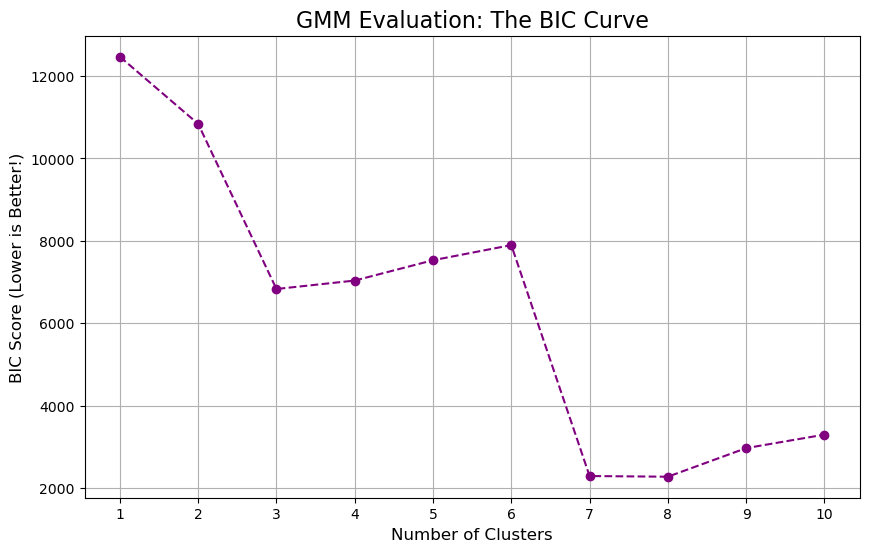

In [5]:
import os
os.environ["OMP_NUM_THREADS"] = "3"

import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')

from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

bic_scores = []
cluster_range = range(1, 11)

# Loop through 1 to 10 clusters to find the best fit
for i in cluster_range:
    # covariance_type='full' allows the bell curves to stretch into ovals, 
    # which is perfect for overlapping data!
    gmm = GaussianMixture(n_components=i, covariance_type='full', random_state=42)
    
    # Fit the model on your perfectly preprocessed 2D array
    gmm.fit(X_processed) 
    
    # Calculate the BIC score and save it
    bic_scores.append(gmm.bic(X_processed))

# Plot the BIC scores
plt.figure(figsize=(10, 6))
plt.plot(cluster_range, bic_scores, marker='o', linestyle='--', color='purple')
plt.title('GMM Evaluation: The BIC Curve', fontsize=16)
plt.xlabel('Number of Clusters', fontsize=12)
plt.ylabel('BIC Score (Lower is Better!)', fontsize=12)
plt.xticks(cluster_range)
plt.grid(True)
plt.show()

In [9]:
from sklearn.mixture import GaussianMixture
gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42)

gmm.fit(X_processed)

probabilities = gmm.predict_proba(X_processed)

y_gmm = gmm.fit_predict(X_processed)

ds['Cluster'] = y_gmm

# Let's look at a "messy" patient (e.g., patient index 42)
patient_42_probs = probabilities[42]

print("Patient 42's Probability Breakdown:")
for i, prob in enumerate(patient_42_probs):
    print(f"Cluster {i}: {prob * 100:.2f}%")

Patient 42's Probability Breakdown:
Cluster 0: 0.00%
Cluster 1: 98.51%
Cluster 2: 0.22%
Cluster 3: 1.27%
Cluster 4: 0.00%


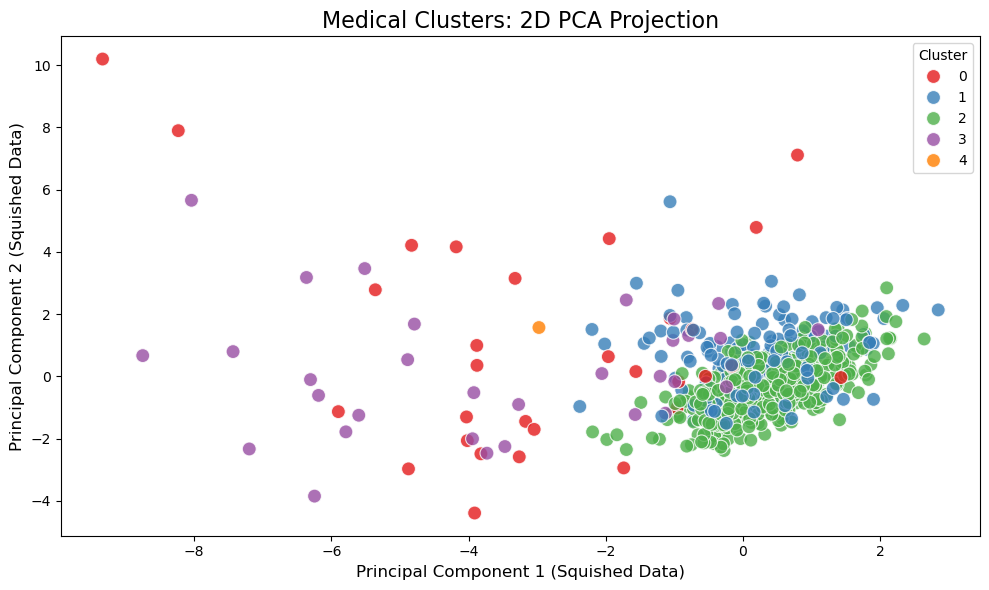

In [10]:
from sklearn.decomposition import PCA

# 1. Initialize PCA to squish our 12D data down to 2 dimensions
pca = PCA(n_components=2)

# 2. Fit and transform your SCALED data (X_processed)
X_pca = pca.fit_transform(X_processed)

# 3. Add these new 2D coordinates to your dataset
ds['PCA1'] = X_pca[:, 0]
ds['PCA2'] = X_pca[:, 1]

# 4. Graph the PCA flat-map!
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=ds, 
    x='PCA1', 
    y='PCA2', 
    hue='Cluster', 
    palette='Set1', 
    s=100, 
    alpha=0.8
)

plt.title('Medical Clusters: 2D PCA Projection', fontsize=16)
plt.xlabel('Principal Component 1 (Squished Data)', fontsize=12)
plt.ylabel('Principal Component 2 (Squished Data)', fontsize=12)
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()